# **What are the most demanded skills for the top 3 data roles?**

**Methodology**
   
   1. Clean-up skills column
   2. Calculate skill count based on job_title_short
   3. Calculate skill percentage
   4. PLot final findings

In [2]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import seaborn as sns
import matplotlib.pyplot as plt

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df =dataset['train'].to_pandas()
def clean_list(skill_list):
    if pd.notna(skill_list):
        return ast.literal_eval(skill_list)

# Cleaning Data
df['job_skills'] = df['job_skills'].apply(clean_list)
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

d:\Anaconda\envs\python_course\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df1 = df[df['job_country'] == 'India'].copy()

In [4]:
df_skills = df1.explode('job_skills')

df_skills[['job_title', 'job_skills']]

,job_title,job_skills
16,Big Data Engineer,powershell
16,Big Data Engineer,python
16,Big Data Engineer,sql
16,Big Data Engineer,mysql
16,Big Data Engineer,sql server
...,...,...
785716,Application Support Analyst,c#
785716,Application Support Analyst,sql
785718,Senior Performance QA Analyst,NaN
785740,AWS System Analyst,aws


In [5]:
df1_job_title_count = df1['job_title_short'].value_counts().reset_index(name='jobs_total')

df1_job_title_count

,job_title_short,jobs_total
0,Data Engineer,19062
1,Data Scientist,13279
2,Data Analyst,6121
3,Senior Data Engineer,4353
4,Senior Data Scientist,2486
5,Business Analyst,1887
6,Software Engineer,1795
7,Senior Data Analyst,1083
8,Machine Learning Engineer,671
9,Cloud Engineer,351


In [6]:
df1_skills_count = df_skills.groupby(['job_skills', 'job_title_short']).size()

df1_skills_count =df1_skills_count.reset_index(name='skill_count')

df1_skills_count.sort_values(by='skill_count', ascending=False, inplace=True)

df1_skills_count

,job_skills,job_title_short,skill_count
1374,sql,Data Engineer,12993
1088,python,Data Engineer,11568
1089,python,Data Scientist,9248
1327,spark,Data Engineer,7157
103,aws,Data Engineer,6993
...,...,...,...
34,angular.js,Data Scientist,1
49,arch,Business Analyst,1
787,mlpack,Data Engineer,1
1679,yarn,Senior Data Scientist,1


In [7]:
df1_skills_perc = pd.merge(df1_skills_count, df1_job_title_count, how='left', on='job_title_short')

df1_skills_perc['skills_percent'] =100 * df1_skills_perc['skill_count']/ df1_skills_perc['jobs_total']

df1_skills_perc

,job_skills,job_title_short,skill_count,jobs_total,skills_percent
0,sql,Data Engineer,12993,19062,68.161788
1,python,Data Engineer,11568,19062,60.686182
2,python,Data Scientist,9248,13279,69.643798
3,spark,Data Engineer,7157,19062,37.545903
4,aws,Data Engineer,6993,19062,36.685552
...,...,...,...,...,...
1684,angular.js,Data Scientist,1,13279,0.007531
1685,arch,Business Analyst,1,1887,0.052994
1686,mlpack,Data Engineer,1,19062,0.005246
1687,yarn,Senior Data Scientist,1,2486,0.040225


In [8]:
job_titles = df1_skills_count['job_title_short'].unique().tolist()

job_titles = sorted(job_titles[:3])

job_titles

['Data Analyst', 'Data Engineer', 'Data Scientist']

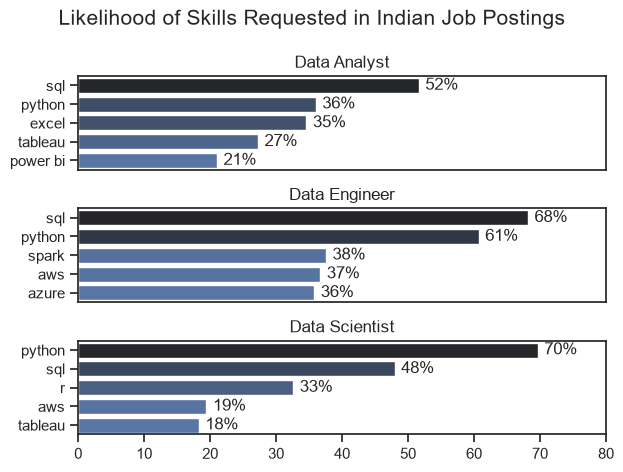

In [16]:
fig, ax=plt.subplots(len(job_titles), 1)

sns.set_theme(style='ticks')

for i, job_title in enumerate(job_titles):
    df_plot = df1_skills_perc[df1_skills_perc['job_title_short'] == job_title].head(5)
    sns.barplot(data=df_plot, x='skills_percent', y='job_skills', ax=ax[i], hue='skill_count', palette='dark:b_r')
    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].get_legend().remove()
    ax[i].set_xlim(0, 80)

    for n, v in enumerate(df_plot['skills_percent']):
        ax[i].text(v +1 , n, f'{v:.0f}%', va='center')

    if i !=len(job_titles) -1:
        ax[i].set_xticks([])

fig.suptitle('Likelihood of Skills Requested in Indian Job Postings', fontsize=15)
fig.tight_layout()
plt.show()